In [1]:
# Open Zsun, 0.45, 0.1 Zsun grids
from posydon.grids.psygrid import PSyGrid
from posydon.config import PATH_TO_POSYDON_DATA
from posydon.utils.common_functions import convert_metallicity_to_string, orbital_separation_from_period
from posydon.popsyn.distributions import PowerLawPeriod
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cmap import Colormap
import pickle
from pathlib import Path
from tqdm import tqdm
from scipy.stats import gaussian_kde
from helper_functions import calc_Teff, optical_depth_calculation

tol_vibrant = Colormap('tol:vibrant')(np.linspace(0, 1, 7))


grid = PSyGrid(f"{PATH_TO_POSYDON_DATA}/HMS-HMS/1e-02_Zsun.h5")

In [3]:
np.unique(grid.initial_values['star_1_mass'])

array([  3.91962324,   4.07412709,   4.23472117,   4.40164555,
         4.57514977,   4.75549318,   4.94294537,   5.13778656,
         5.34030801,   5.55081245,   5.76961457,   5.76961457,
         5.99704143,   6.23343302,   6.47914269,   6.73453776,
         7.        ,   7.27592624,   7.56272895,   7.86083686,
         8.17069559,   8.49276835,   8.82753659,   9.17550073,
         9.53718093,   9.91311785,  10.30387347,  10.71003191,
        11.13220031,  11.13220031,  11.57100977,  12.02711622,
        12.5012015 ,  12.99397429,  13.50617122,  14.03855794,
        15.76497338,  17.70369769,  19.8808399 ,  22.32571986,
        22.32571986,  25.07126308,  28.15444413,  31.61678459,
        35.50491224,  39.87118896,  44.77441597,  44.77441597,
        50.28062562,  56.46397073,  56.46397073,  63.40772318,
        63.40772318,  71.20539535,  79.96199946,  89.7954618 ,
       100.83821083, 100.83821083, 113.23896062, 127.16471363,
       142.80300971, 160.36445173, 180.08554184, 202.23

In [6]:
period_value = 2.68269580e+01 # days
M1_value = 31.61678459 # Msun
q_value = 0.9 # M2/M1
M2_value = M1_value * q_value
print(M1_value, M2_value, period_value)
print(f"Period: {period_value} days, M1: {M1_value} Msun, M2: {M2_value} Msun")

31.61678459 28.455106131 26.826958
Period: 26.826958 days, M1: 31.61678459 Msun, M2: 28.455106131 Msun


In [7]:
# in Zsun find the closest model to the given period, M1, and M2

data = grid.initial_values[['period_days', "star_1_mass", "star_2_mass"]]
# print(np.unique(Zsun_data['period_days']))
# print(np.unique(Zsun_data['star_1_mass']))
# print(np.unique(Zsun_data['star_2_mass']))


# Find the closest model in Zsun grid
P_mask = np.isclose(data['period_days'], period_value, atol=0.1)
M1_mask = np.isclose(data['star_1_mass'], M1_value, atol=1)
M2_mask = np.isclose(data['star_2_mass'], M2_value, atol=1)

model_id = np.where(P_mask & M1_mask & M2_mask)[0][0]


In [17]:
model.binary_history.dtype.names

('model_number',
 'age',
 'star_1_mass',
 'star_2_mass',
 'period_days',
 'binary_separation',
 'lg_system_mdot_1',
 'lg_system_mdot_2',
 'lg_wind_mdot_1',
 'lg_wind_mdot_2',
 'lg_mstar_dot_1',
 'lg_mstar_dot_2',
 'lg_mtransfer_rate',
 'xfer_fraction',
 'rl_relative_overflow_1',
 'rl_relative_overflow_2',
 'trap_radius',
 'acc_radius',
 't_sync_rad_1',
 't_sync_conv_1',
 't_sync_rad_2',
 't_sync_conv_2')

Primary has depleted central carbon


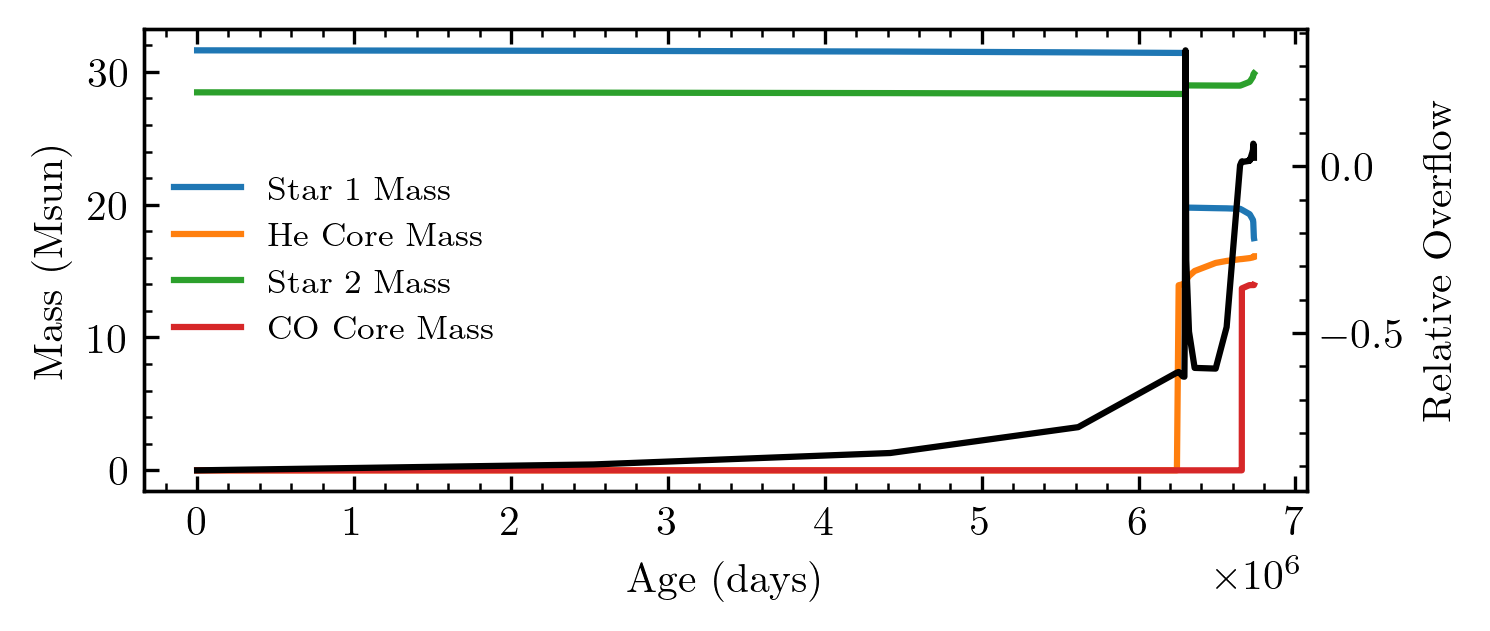

In [22]:
model = grid[model_id]


fig, ax = plt.subplots(figsize=(5, 2))
print(grid.final_values['termination_flag_1'][model_id])
ax.plot(model.binary_history['age'], model.binary_history['star_1_mass'], label='Star 1 Mass')
ax.plot(model.binary_history['age'], model.history1['he_core_mass'], label='He Core Mass')
ax.plot(model.binary_history['age'], model.binary_history['star_2_mass'], label='Star 2 Mass')
ax.plot(model.binary_history['age'], model.history1['co_core_mass'], label='CO Core Mass')

ax2 = ax.twinx()

ax2.plot(model.binary_history['age'], model.binary_history['rl_relative_overflow_1'], color='black')


ax.set_xlabel('Age (days)')
ax.set_ylabel('Mass (Msun)')
ax2.set_ylabel('Relative Overflow')
ax.legend()
plt.show()

In [1]:
from posydon.utils.common_functions import convert_metallicity_to_string, orbital_separation_from_period
from posydon.popsyn.distributions import PowerLawPeriod
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cmap import Colormap
import pickle
from pathlib import Path
from tqdm import tqdm
from scipy.stats import gaussian_kde
from helper_functions import calc_Teff, optical_depth_calculation

tol_vibrant = Colormap('tol:vibrant')(np.linspace(0, 1, 7))

COLORS = {0.0001: '#1f4e79',
           0.001: '#2e75b6',
            0.01: '#5ba3d0', 
             0.1: '#f4a261',
             0.2: '#e76f51',
            0.45: '#c0392b', 
             1.0: '#8e1a0e',
             2.0: '#5c0a0a'
             }

In [2]:
def load_metallicity(metallicity, data_folder):
    """Load and process WR phase data for a single metallicity.

    Returns a dict of arrays ready for analysis.
    """
    met_str = convert_metallicity_to_string(metallicity)
    file_path = data_folder / f'WR_phases_Z{met_str}_Zsun.pkl'
    with open(file_path, 'rb') as f:
        data = pickle.load(f)

    S1_WR_data = data['S1_WR_data']
    S2_WR_data = data['S2_WR_data']

    s1 = pd.concat(S1_WR_data.values(), keys=S1_WR_data.keys())
    s2 = pd.concat(S2_WR_data.values(), keys=S2_WR_data.keys())

    s1_Teff = 10**calc_Teff(s1['S1_log_L'], s1['S1_log_R'])
    s1_sep  = orbital_separation_from_period(s1['orbital_period'].values,
                                              s1['S1_mass'].values,
                                              s1['S2_mass'].values)
    s2_Teff = 10**calc_Teff(s2['S2_log_L'], s2['S2_log_R'])
    s2_sep  = orbital_separation_from_period(s2['orbital_period'].values,
                                              s2['S2_mass'].values,
                                              s2['S1_mass'].values)

    return {
        'time':             np.concatenate([s1['time'].values,               s2['time'].values]),
        'weight':           np.concatenate([s1['weight'].values,             s2['weight'].values]),
        'state':            np.concatenate([s1['state'].values,              s2['state'].values]),
        'key':              np.concatenate([s1.index.get_level_values(0),    s2.index.get_level_values(0)]),
        'star':             np.array(['S1'] * len(s1) + ['S2'] * len(s2)),
        'period':           np.concatenate([s1['orbital_period'].values,     s2['orbital_period'].values]),
        'separation':       np.concatenate([s1_sep,                          s2_sep]),
        'Teff':             np.concatenate([s1_Teff.values,                  s2_Teff.values]),
        'L':                np.concatenate([10**s1['S1_log_L'].values,       10**s2['S2_log_L'].values]),
        'optical_depth':    np.concatenate([s1['optical_depth'].values,      s2['optical_depth'].values]),
        'surface_H':        np.concatenate([s1['S1_surface_h1'].values,      s2['S2_surface_h1'].values]),
        'surface_He':       np.concatenate([s1['S1_surface_he4'].values,     s2['S2_surface_he4'].values]),
        'mass':             np.concatenate([s1['S1_mass'].values,            s2['S2_mass'].values]),
        'mass_companion':   np.concatenate([s1['S2_mass'].values,            s2['S1_mass'].values]),
        'radius':           np.concatenate([10**s1['S1_log_R'].values,       10**s2['S2_log_R'].values]),
        'Mdot':             np.concatenate([10**s1['S1_lg_mdot'].values,     10**s2['S2_lg_mdot'].values]),
        'companion':        np.concatenate([s1['S2_state'].values,           s2['S1_state'].values]),
        'S1_state':         np.concatenate([s1['S1_state'].values,           s2['S2_state'].values]),
        'model_weight':     np.concatenate([s1['model_weight'].values,       s2['model_weight'].values]),
    }


data_folder = Path('/Users/max/Documents/projects/WR_population/data/optical_depth_test/')
metallicities = [0.01, 0.1, 0.2, 0.45, 1.0]#[0.01, 0.1, 0.2, 0.45, 1.0]  # in units of Zsun

WR_data = {Z: load_metallicity(Z, data_folder) for Z in metallicities}

In [3]:
def make_binary_mask(d):
    """Return mask for detached/RLO/contact binaries."""
    s = d['state']
    return (s == 'detached') | (s == 'RLO1') | (s == 'contact') | (s == 'RLO2')

def classify_WR(d):
    """Return WNL, WNE, WC boolean masks for a data dict from load_metallicity."""
    WNL = (
        (d['surface_H'] > 0.05) & (d['surface_H'] <= 0.5)
        & (d['optical_depth'] > 1.5)
        & ~pd.Series(d['S1_state']).str.contains('H_burning', na=False).values
    )
    WNE = (d['surface_H'] <= 0.05) & (d['surface_He'] >= 0.7) & (d['optical_depth'] > 1.5)
    WC  = (d['surface_H'] <= 0.05) & (d['surface_He'] <  0.7) & (d['optical_depth'] > 1.5)
    return WNL, WNE, WC



In [14]:
WR_data[0.2]['key']

array([    0,     0,     0, ..., 99999, 99999, 99999])

In [21]:
keys = np.unique(WR_data[0.2]['key'])

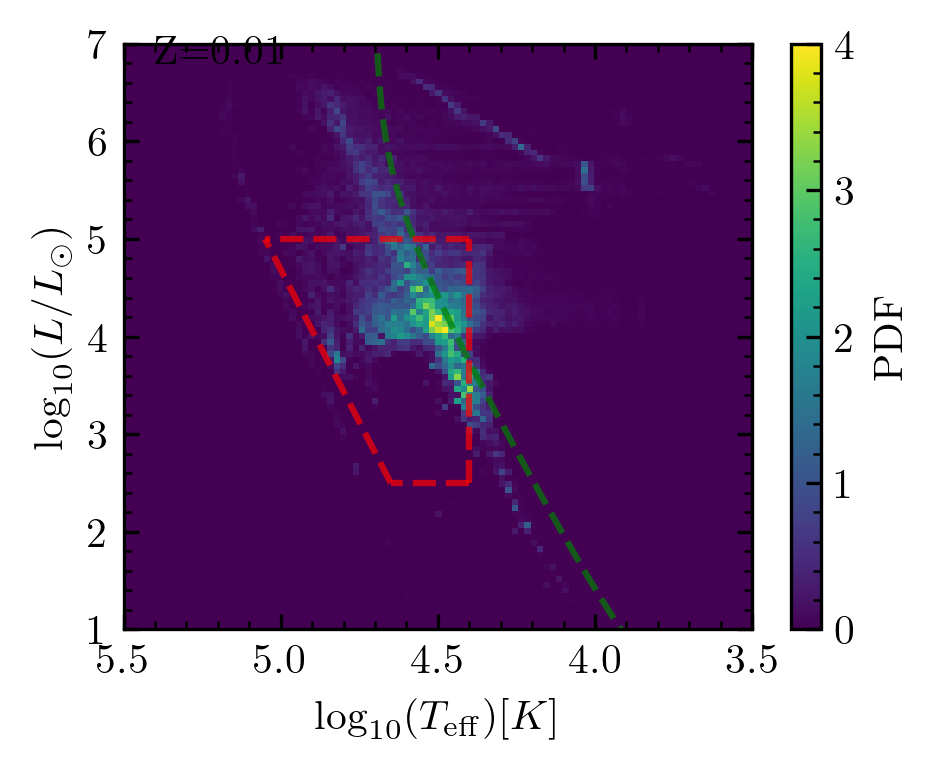

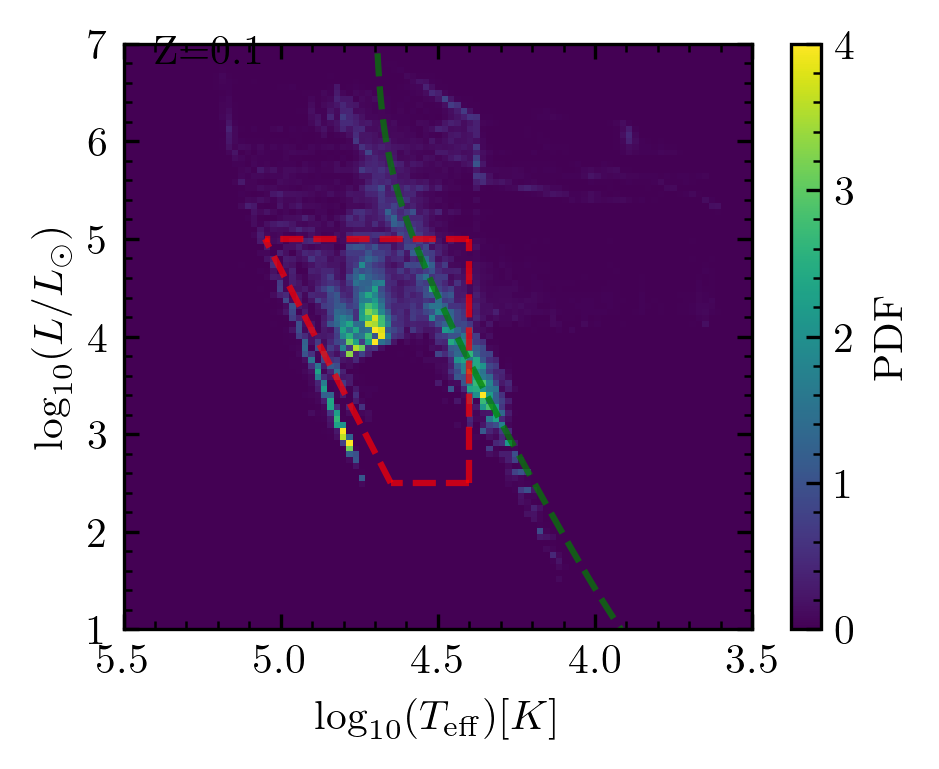

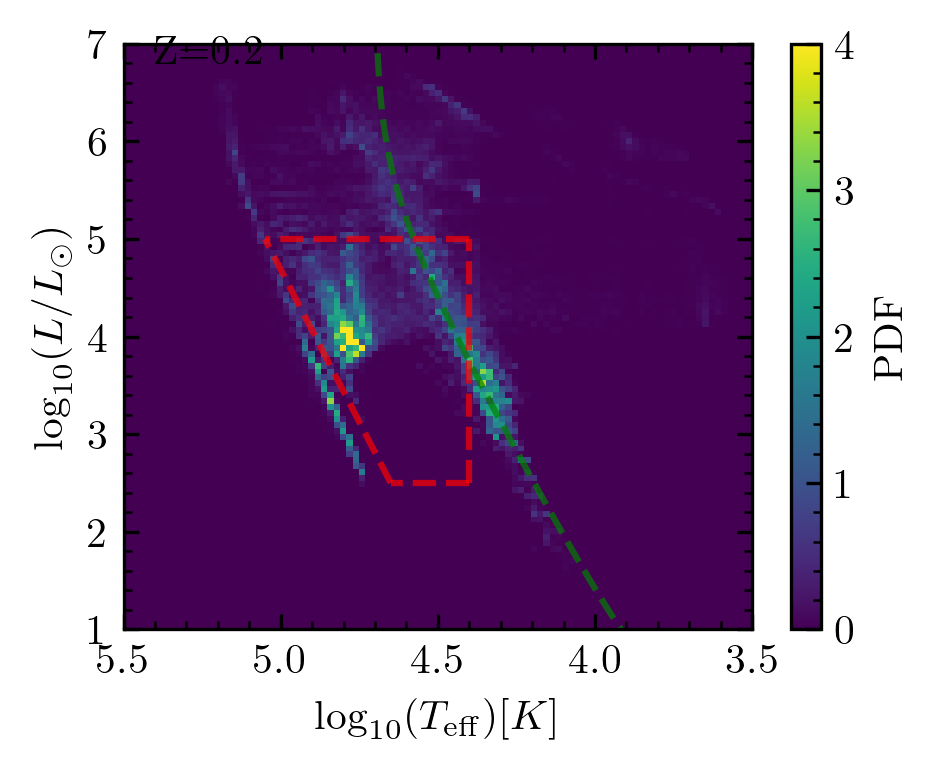

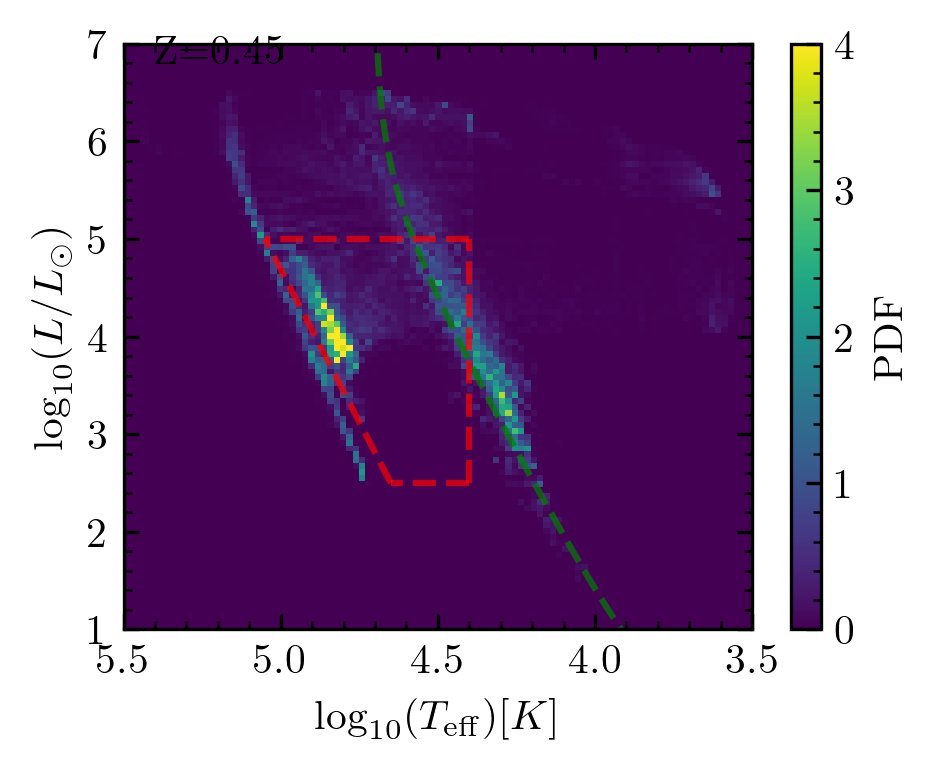

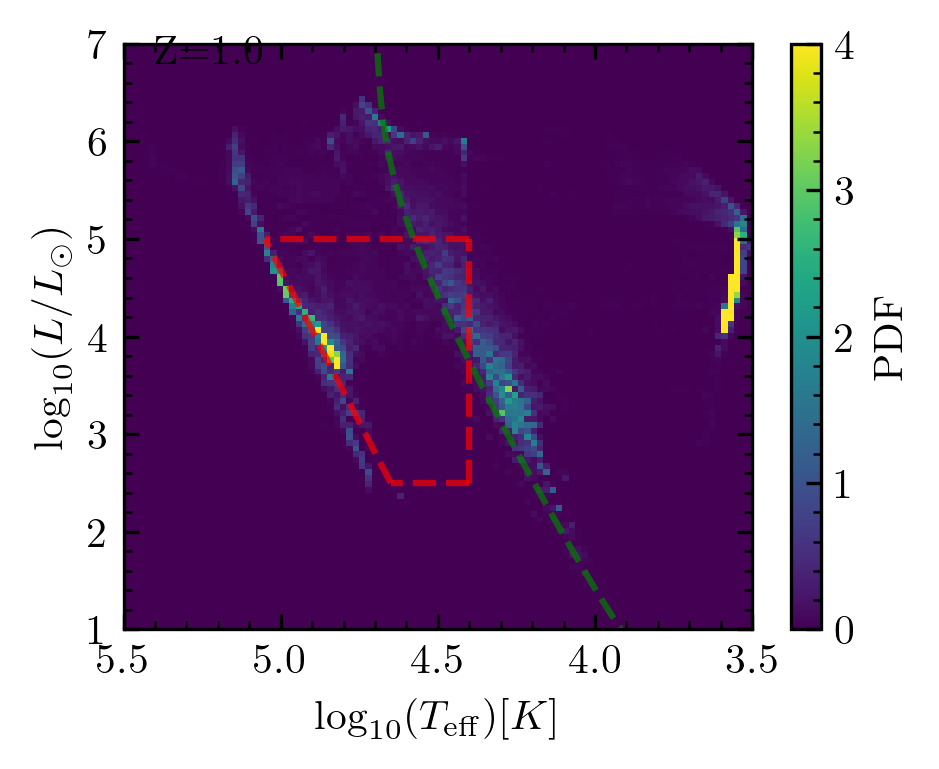

<Figure size 1014x760.5 with 0 Axes>

In [82]:
from helper_functions import tout_L_ZAMS, tout_R_ZAMS

#plt.plot(np.log10(WR_data[0.2]['Teff'][:100]), np.log10(WR_data[0.2]['L'][:100]), s=1

xbins = np.linspace(3.5, 5.5, 100)
ybins = np.linspace(1, 7, 100)
for met in metallicities:
    h, xedges, yedges = np.histogram2d(np.log10(WR_data[met]['Teff']),np.log10(WR_data[met]['L']), 
                                       weights=WR_data[met]['weight'], bins=[xbins, ybins],density=True)
    plt.imshow(h.T, origin='lower', extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]], aspect='auto', vmin=0, vmax=4)


    M_zams = np.logspace(0.08, 2.5, 100) 
    L_zams = tout_L_ZAMS(M_zams)
    R_zams = tout_R_ZAMS(M_zams)

    # # Hurley et al. (2000) for ZAMS Teff (derived from their radius formula)
    # # log(Teff) approximation for MS stars
    log_Teff_zams = calc_Teff(np.log10(L_zams), np.log10(R_zams))
    log_L_zams = np.log10(L_zams)

    plt.plot(log_Teff_zams, log_L_zams, 'g--', linewidth=1.5, label='ZAMS', alpha=0.7)
    plt.xlabel('$\log_{10}(T_\mathrm{eff}) [K]$')
    plt.ylabel('$\log_{10}(L/L_\odot)$')
    plt.xlim(5.5, 3.5)
    plt.ylim(1, 7)
    plt.text(5.4, 6.8, f'Z={met}')
    plt.plot([4.4, 4.65], [2.5, 2.5], color='red', linestyle='--', alpha=0.7)
    plt.plot([4.4, 4.4], [2.5, 5], color='red', linestyle='--', alpha=0.7)
    plt.plot([4.65, 5.05], [2.5, 5], color='red', linestyle='--', alpha=0.7)
    plt.plot([4.4, 5.05], [5, 5], color='red', linestyle='--', alpha=0.7)
    plt.colorbar(label='PDF')
    plt.show()
    plt.clf()